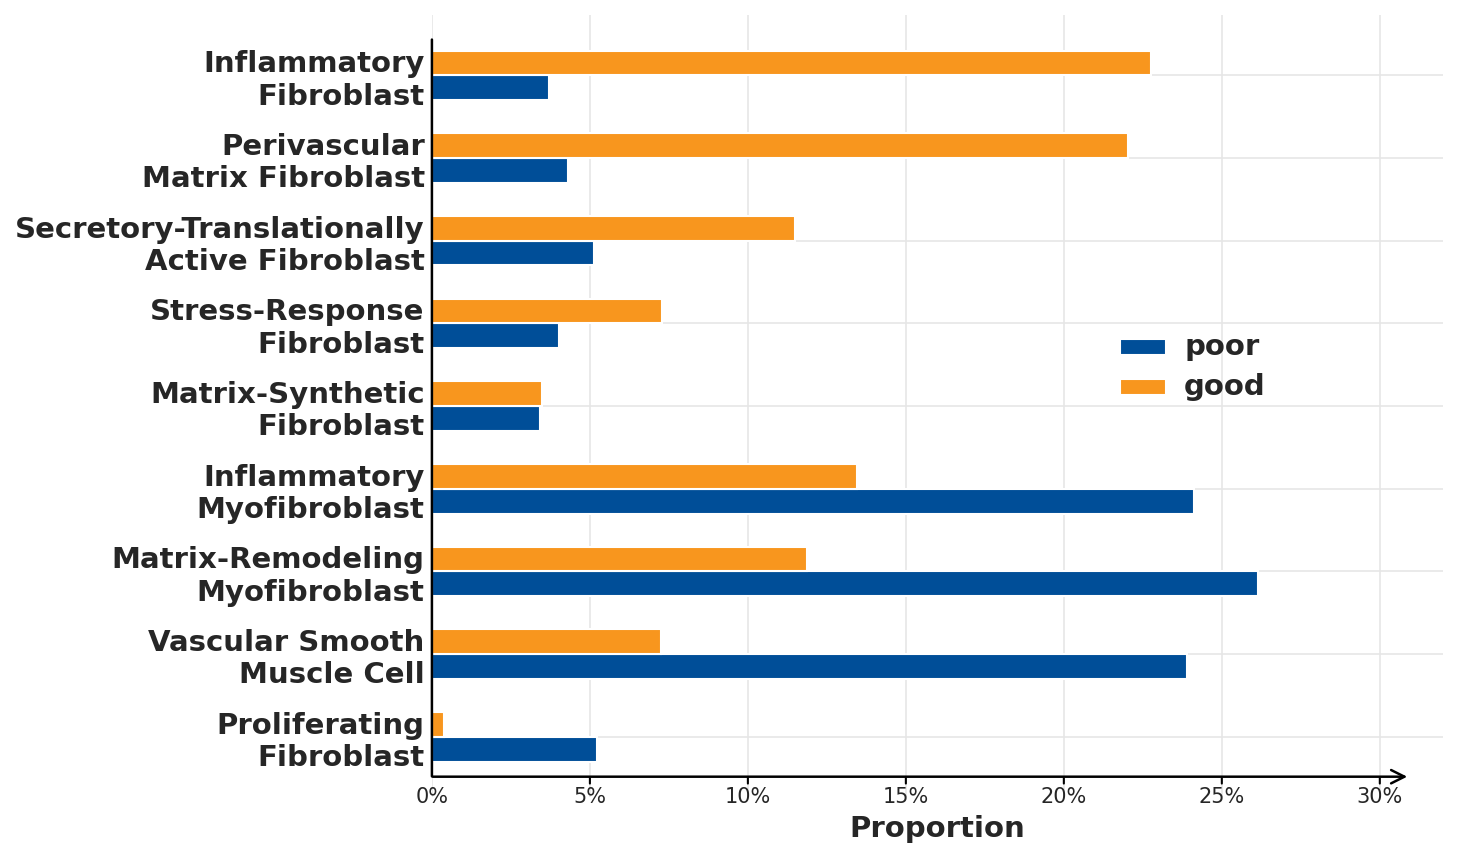

In [86]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scanpy as sc

# 0. Load data
adata = sc.read("./h5ad/adata_fibroblast.h5ad")

# 1. Prepare batch-to-effect mapping dictionary
batch2effect = {
    "H-nS10": "poor",
    "H-nS07": "good",
    "Q-nS01": "poor",
    "H-nS08": "good",
    'H-nS03': "good",
    'H-nS09': "poor",
    'Q-nS04': "good",
    'H-nS01': "poor",
    'Q-nS02': "poor",
    'Q-nS03': "good",
    "H-nS06": "good"
}

# 2. Map and calculate proportions
adata.obs['effect'] = adata.obs['batch'].map(batch2effect)
adata_temp = adata.obs.dropna(subset=['effect'])

df_counts = pd.crosstab(adata_temp['effect'], adata_temp['celltype'])
df_prop = df_counts.div(df_counts.sum(axis=1), axis=0).T

# 3. Sort by specified order
my_order = ['Inflammatory Fibroblast',
            'Perivascular Matrix Fibroblast',
            'Secretory-Translationally Active Fibroblast',
            'Stress-Response Fibroblast',
            'Matrix-Synthetic Fibroblast',
            'Inflammatory Myofibroblast',
            'Matrix-Remodeling Myofibroblast',
            'Vascular Smooth Muscle Cell',
            'Proliferating Fibroblast'
][::-1]
df_sorted = df_prop.loc[my_order]

# 4. Prepare data for same-direction plotting
cell_types = df_sorted.index
bar_height = 0.45  # height of a single bar
group_gap = 0.6    # gap between groups
# No intra-group gap, two bars are adjacent; inter-group gap is applied
y_pos = np.arange(len(cell_types)) * (2 * bar_height + group_gap)

# 5. Start plotting (width: 10, height: 6)
fig, ax = plt.subplots(figsize=(10, 6), dpi=150)

# Draw 'poor' group (lower bar)
ax.barh(y_pos, df_sorted['poor'], height=bar_height, color='#004E98', align='center', label='poor')
# Draw 'good' group (upper bar, adjacent to poor)
ax.barh(y_pos + bar_height, df_sorted['good'], height=bar_height, color='#F8961E', align='center', label='good')

# 6. Style adjustments
# Center Y-axis labels in the middle of each group
ax.set_yticks(y_pos + bar_height / 2)
ax.set_yticklabels(cell_types, fontsize=10, fontweight='bold')  # Bold Y-axis labels

# X-axis ticks and labels
ax.set_xticks([0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3])
ax.set_xticklabels(['0%', '5%', '10%', '15%', '20%', '25%', '30%'], fontsize=10)
ax.set_xlabel('Proportion', fontsize=14, fontweight='bold')  # Bold Proportion
ax.set_xlim(0, 0.32)

# Legend
legend = ax.legend(loc='center left', bbox_to_anchor=(0.66, 0.55), fontsize=11, frameon=False)
for text in legend.get_texts():
    text.set_fontweight('bold')  # Bold poor and good in legend
    text.set_fontsize(14)

# Hide default spines
for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(axis='y', length=0)

# Draw bottom X-axis line with arrow
ax.annotate(
    '', xy=(0.31, -0.5), xytext=(-0.001, -0.5),
    xycoords='data',
    arrowprops=dict(arrowstyle='->', lw=1.2, color='black')
)

ax.annotate(
    '', xy=(0.000, y_pos[-1] + bar_height+0.5), xytext=(0.000, -0.57),
    xycoords='data',
    arrowprops=dict(arrowstyle='-', lw=1.2, color='black')
)

cell_types_wrapped = []
for c in cell_types:
    if ' ' not in c:
        cell_types_wrapped.append(c)
    else:
        spaces = [i for i, ch in enumerate(c) if ch == ' ']
        mid = len(c) / 2
        # Find the space closest to the center
        split_pos = min(spaces, key=lambda x: abs(x - mid))
        cell_types_wrapped.append(c[:split_pos] + '\n' + c[split_pos+1:])

ax.set_yticklabels(cell_types_wrapped, fontsize=14, fontweight='bold')  # Bold wrapped Y-axis labels

# Manually draw X-axis tick lines (extending downward)
xticks_pos = [0.05, 0.1, 0.15, 0.2, 0.25, 0.3]
for x in xticks_pos:
    ax.annotate(
        '', xy=(x, -0.7), xytext=(x, -0.45),
        xycoords='data',
        arrowprops=dict(arrowstyle='-', lw=1.0, color='black')
    )
ax.tick_params(axis='x', direction='out', length=0, pad=-5)
plt.tight_layout()
plt.show()